In [1]:
%pip install pandas numpy seaborn scikit-learn nltk lime shap
%pip install torch "transformers>=4.40"
%pip install tf-keras

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import re
import random
import seaborn as sns
import matplotlib.pyplot as plt
import shap
import torch

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from lime.lime_text import LimeTextExplainer

from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

# Reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

c:\Users\LUIRYS SILVA\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cpu


In [8]:
df = pd.read_csv('../all-data.csv')

In [9]:
df.head()

,sentiment,text
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


In [10]:
df.shape

(4846, 2)

<Axes: xlabel='sentiment', ylabel='count'>

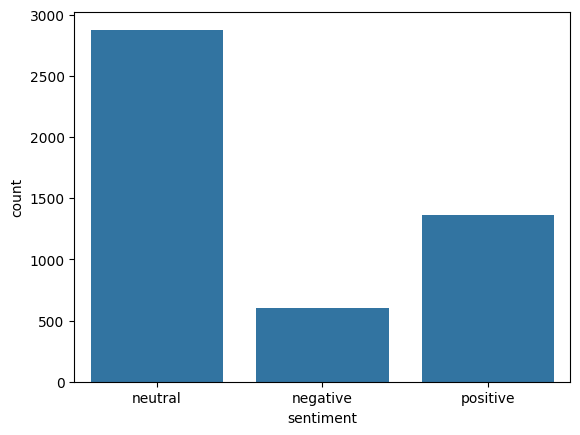

In [11]:
sns.countplot(x='sentiment', data = df)

**Pré-Processamento**

In [12]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("wordnet")
nltk.download('punkt_tab')

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    tokens = word_tokenize(text)
    stop_words = set(stopwords.words("english"))
    tokens = [word for word in tokens if word not in stop_words]
    lemmatizer = WordNetLemmatizer()
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(preprocess_text)

# Texto que vai para o DistilBERT: "text" (recomendado) ou "clean_text"
TEXT_COLUMN = "text"

[nltk_data] Downloading package stopwords to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\LUIRYS
[nltk_data]     SILVA\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [13]:
le = LabelEncoder()
df['label_encoded'] = le.fit_transform(df['sentiment'])
le.classes_

array(['negative', 'neutral', 'positive'], dtype=object)

In [14]:
df.head(5)

,sentiment,text,clean_text,label_encoded
0,neutral,"According to Gran , the company has no plans t...",according gran company plan move production ru...,1
1,neutral,Technopolis plans to develop in stages an area...,technopolis plan develop stage area less squar...,1
2,negative,The international electronic industry company ...,international electronic industry company elco...,0
3,positive,With the new production plant the company woul...,new production plant company would increase ca...,2
4,positive,According to the company 's updated strategy f...,according company updated strategy year baswar...,2


**Divisão treino/teste**

In [15]:
X = df[TEXT_COLUMN]
y = df['label_encoded']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#, stratify=y

# Conferência: o exemplo 499 deve ser o mesmo tweet usado no MLP
print("Índice original do exemplo 499:", X_test.index[499])
print("clean_text (como no MLP):", df.loc[X_test.index[499], "clean_text"])
print("Texto que o DistilBERT verá:", X_test.iloc[499])

Índice original do exemplo 499: 2698
clean_text (como no MLP): preliminary estimation technology park measure square meter
Texto que o DistilBERT verá: Under a preliminary estimation , the technology park will measure about 50,000 square meters .


In [16]:
# Validação = 10% finais do treino, exatamente como validation_split=0.1 do Keras
split_at = int(len(X_train) * (1 - 0.1))
X_tr, X_val = X_train.iloc[:split_at], X_train.iloc[split_at:]
y_tr, y_val = y_train.iloc[:split_at], y_train.iloc[split_at:]
print("Treino:", len(X_tr), "| Validação:", len(X_val), "| Teste:", len(X_test))

Treino: 3488 | Validação: 388 | Teste: 970


**Tokenização**

In [17]:
MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Verificar o tamanho dos tweets em tokens para escolher MAX_LEN
lens = [len(tokenizer.encode(t)) for t in X_train]
print("Percentis 50/95/99/máx:", np.percentile(lens, [50, 95, 99]), max(lens))

MAX_LEN = 64
print(f"Tweets cobertos sem truncar: {np.mean(np.array(lens) <= MAX_LEN):.2%}")

Percentis 50/95/99/máx: [28. 57. 69.] 150
Tweets cobertos sem truncar: 97.94%


In [18]:
class TweetDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, padding="max_length",
                             max_length=MAX_LEN, return_tensors="pt")
        self.labels = torch.tensor(list(labels), dtype=torch.long)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = self.labels[i]
        return item

BATCH_SIZE = 32  # mesmo batch do MLP; reduza para 16 se faltar memória

train_loader = DataLoader(TweetDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TweetDataset(X_val, y_val), batch_size=BATCH_SIZE)

**DistilBERT**

In [19]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_),
    id2label={i: c for i, c in enumerate(le.classes_)},
    label2id={c: i for i, c in enumerate(le.classes_)},
    attn_implementation="eager",   # necessário para extrair os pesos de atenção
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Parâmetros: {n_params:,}")

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Parâmetros: 66,955,779


In [20]:
# Hiperparâmetros usuais de fine-tuning
EPOCHS = 3
LR = 2e-5

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    tot_loss, correct, n = 0.0, 0, 0
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.set_grad_enabled(train):
            out = model(**batch)
            if train:
                optimizer.zero_grad()
                out.loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
        bs = batch["labels"].size(0)
        tot_loss += out.loss.item() * bs
        correct += (out.logits.argmax(-1) == batch["labels"]).sum().item()
        n += bs
    return tot_loss / n, correct / n

history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
best_val_loss, best_state = float("inf"), None

for epoch in range(EPOCHS):
    loss, acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    for k, v in zip(history, [loss, acc, val_loss, val_acc]):
        history[k].append(v)
    print(f"Epoch {epoch+1}/{EPOCHS} - accuracy: {acc:.4f} - loss: {loss:.4f} "
          f"- val_accuracy: {val_acc:.4f} - val_loss: {val_loss:.4f}")
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

# Restaura a época com menor val_loss (defina RESTORE_BEST=False para usar a última, como no MLP)
RESTORE_BEST = True
if RESTORE_BEST:
    model.load_state_dict(best_state)
    print("Modelo restaurado para a melhor época (menor val_loss).")

Epoch 1/3 - accuracy: 0.6514 - loss: 0.7704 - val_accuracy: 0.8196 - val_loss: 0.4758
Epoch 2/3 - accuracy: 0.8526 - loss: 0.3921 - val_accuracy: 0.8479 - val_loss: 0.3617
Epoch 3/3 - accuracy: 0.9017 - loss: 0.2733 - val_accuracy: 0.8479 - val_loss: 0.3745
Modelo restaurado para a melhor época (menor val_loss).


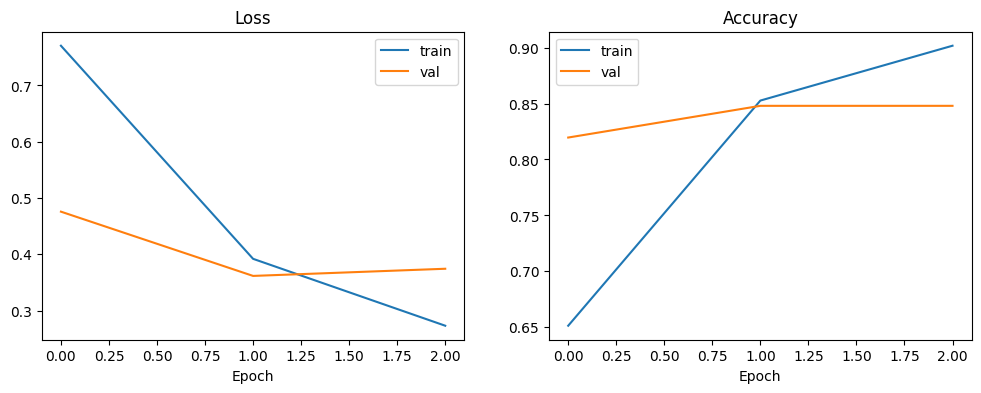

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history["accuracy"], label="train"); ax[1].plot(history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

**Métricas**

In [22]:
@torch.no_grad()
def predict_proba(texts, batch_size=64):
    """Recebe lista de strings e devolve probabilidades (n, 3). Usada nas métricas, no LIME e no SHAP."""
    model.eval()
    texts = [str(t) for t in texts]
    probs = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i+batch_size], truncation=True, padding=True,
                        max_length=MAX_LEN, return_tensors="pt").to(device)
        probs.append(torch.softmax(model(**enc).logits, dim=-1).cpu().numpy())
    return np.vstack(probs)

y_pred = predict_proba(X_test.tolist())
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

              precision    recall  f1-score   support

           0       0.77      0.81      0.79       110
           1       0.89      0.86      0.87       571
           2       0.76      0.80      0.78       289

    accuracy                           0.83       970
   macro avg       0.81      0.82      0.81       970
weighted avg       0.84      0.83      0.83       970



In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score
def calculate_metrics(y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    return accuracy, precision, recall, f1

accuracy, precision, recall, f1 = calculate_metrics(y_test, y_pred_classes)
print(f"Acurácia: {accuracy:.4f}")
print(f"Precisão: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"F1-Score (macro): {f1_score(y_test, y_pred_classes, average='macro'):.4f}  # mais sensível ao desbalanceamento")

Acurácia: 0.8340
Precisão: 0.8367
Recall: 0.8340
F1-Score: 0.8350
F1-Score (macro): 0.8127  # mais sensível ao desbalanceamento


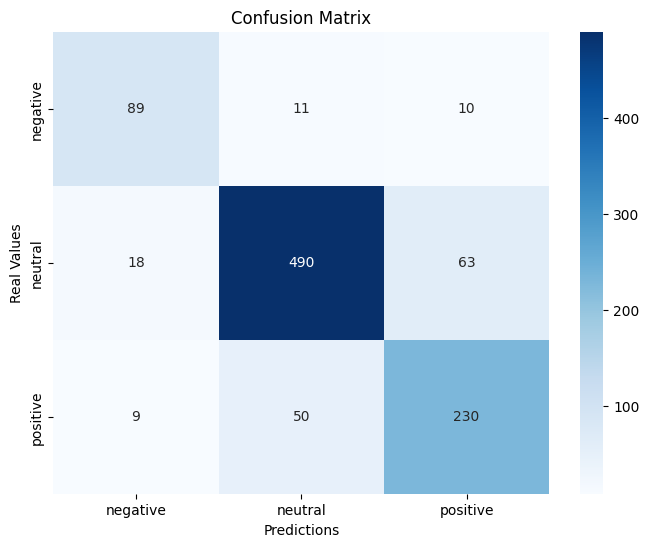

In [24]:
conf_matrix = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predictions")
plt.ylabel("Real Values")
plt.title("Confusion Matrix")
plt.show()

**LIME**

In [25]:
explainer = LimeTextExplainer(class_names=le.classes_)

idx = int(input(f"Digite o número da linha (0 a {len(X_test)-1}): ") or 499)
sample_text = X_test.iloc[idx]
sample_label = y_test.iloc[idx]

pred_probs = predict_proba([sample_text])
pred_class_idx = pred_probs.argmax(axis=1)[0]
pred_class_name = le.classes_[pred_class_idx]

print(f"Número da linha no X_test: {idx}")
print(f"Original text:\n{sample_text}")
print(f"Classe real: {le.classes_[sample_label]}")
print(f"Classe predita: {pred_class_name}")
print("Probabilidades:", pred_probs[0])

# labels=(pred_class_idx,) explica a classe predita (no MLP o LIME explicou a classe 1 por padrão)
explanation = explainer.explain_instance(
    sample_text,
    predict_proba,
    num_features=10,
    labels=(pred_class_idx,)
)

lime_features = explanation.as_list(label=pred_class_idx)
print(lime_features)

Número da linha no X_test: 499
Original text:
Under a preliminary estimation , the technology park will measure about 50,000 square meters .
Classe real: neutral
Classe predita: neutral
Probabilidades: [0.00555992 0.9697632  0.02467693]
[(np.str_('will'), -0.004609127820607683), (np.str_('measure'), 0.004490368027587423), (np.str_('square'), 0.0033835034603140355), (np.str_('about'), 0.0029342589849083293), (np.str_('estimation'), -0.0025698513545062305), (np.str_('Under'), -0.00226472344819663), (np.str_('technology'), -0.0012645700363334595), (np.str_('meters'), 0.00088762591289161), (np.str_('a'), 0.0008416705610110256), (np.str_('park'), -0.0006628349886327743)]


Palavras mais importantes e seus pesos:
will: -0.0046
measure: 0.0045
square: 0.0034
about: 0.0029
estimation: -0.0026
Under: -0.0023
technology: -0.0013
meters: 0.0009
a: 0.0008
park: -0.0007


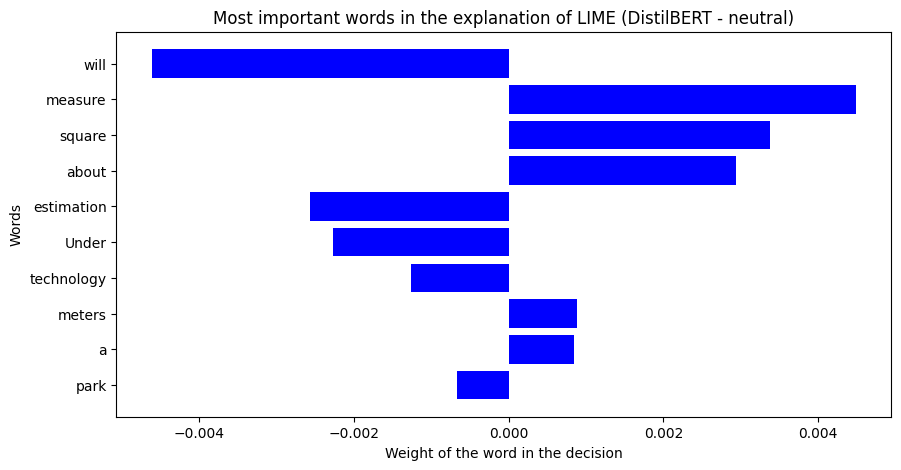

In [26]:
print("Palavras mais importantes e seus pesos:")
for word, weight in lime_features:
    print(f"{word}: {weight:.4f}")

words, weights = zip(*lime_features)
plt.figure(figsize=(10, 5))
plt.barh(words, weights, color="blue")
plt.xlabel("Weight of the word in the decision")
plt.ylabel("Words")
plt.title(f"Most important words in the explanation of LIME (DistilBERT - {pred_class_name})")
plt.gca().invert_yaxis()
plt.show()

**Attention Viz**

In [27]:
lime_idx = 499
sample_text = X_test.iloc[lime_idx]
print("Texto usado na explicação:")
print(sample_text)

enc = tokenizer(sample_text, return_tensors="pt", truncation=True, max_length=MAX_LEN).to(device)
model.eval()
with torch.no_grad():
    out = model(**enc, output_attentions=True)

predicted_class_index = out.logits.argmax(-1).item()
print(f"\nClasse prevista: {predicted_class_index} ({le.classes_[predicted_class_index]})")
print("Probabilidades:", torch.softmax(out.logits, -1)[0].cpu().numpy())

# (camadas, cabeças, seq, seq)
att = torch.stack(out.attentions)[:, 0].cpu()
print("Atenções:", tuple(att.shape))

# 1) Última camada: [CLS] -> tokens, média das cabeças
last_cls = att[-1].mean(0)[0].numpy()

# 2) Attention rollout
seq = att.shape[-1]
rollout = torch.eye(seq)
for layer in att:
    a = layer.mean(0) + torch.eye(seq)
    a = a / a.sum(-1, keepdim=True)
    rollout = a @ rollout
rollout_cls = rollout[0].numpy()

tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])

def merge_subwords(tokens, scores):
    """Junta subpalavras (##) em palavras somando os escores e remove [CLS]/[SEP]."""
    words, vals = [], []
    for t, s in zip(tokens, scores):
        if t in ("[CLS]", "[SEP]", "[PAD]"):
            continue
        if t.startswith("##") and words:
            words[-1] += t[2:]; vals[-1] += s
        else:
            words.append(t); vals.append(s)
    return words, np.array(vals)

w_last, v_last = merge_subwords(tokens, last_cls)
w_roll, v_roll = merge_subwords(tokens, rollout_cls)

importancias = pd.DataFrame({"Feature": w_last, "Last layer [CLS]": v_last, "Rollout": v_roll})
importancias = importancias.sort_values(by="Rollout", ascending=False)
print(importancias.head(20))

Texto usado na explicação:
Under a preliminary estimation , the technology park will measure about 50,000 square meters .

Classe prevista: 1 (neutral)
Probabilidades: [0.00555992 0.9697632  0.02467693]
Atenções: (6, 12, 19, 19)
        Feature  Last layer [CLS]   Rollout
16            .          0.080920  0.079650
5           the          0.072485  0.036108
4             ,          0.071436  0.034060
8          will          0.070024  0.029939
9       measure          0.127490  0.029657
1             a          0.059681  0.028821
12            ,          0.006327  0.025074
3    estimation          0.086827  0.024711
0         under          0.056739  0.023882
15       meters          0.021921  0.023295
7          park          0.038817  0.022954
2   preliminary          0.079655  0.022177
10        about          0.078419  0.021672
6    technology          0.013265  0.020729
13          000          0.014375  0.019516
14       square          0.016882  0.018025
11           50        

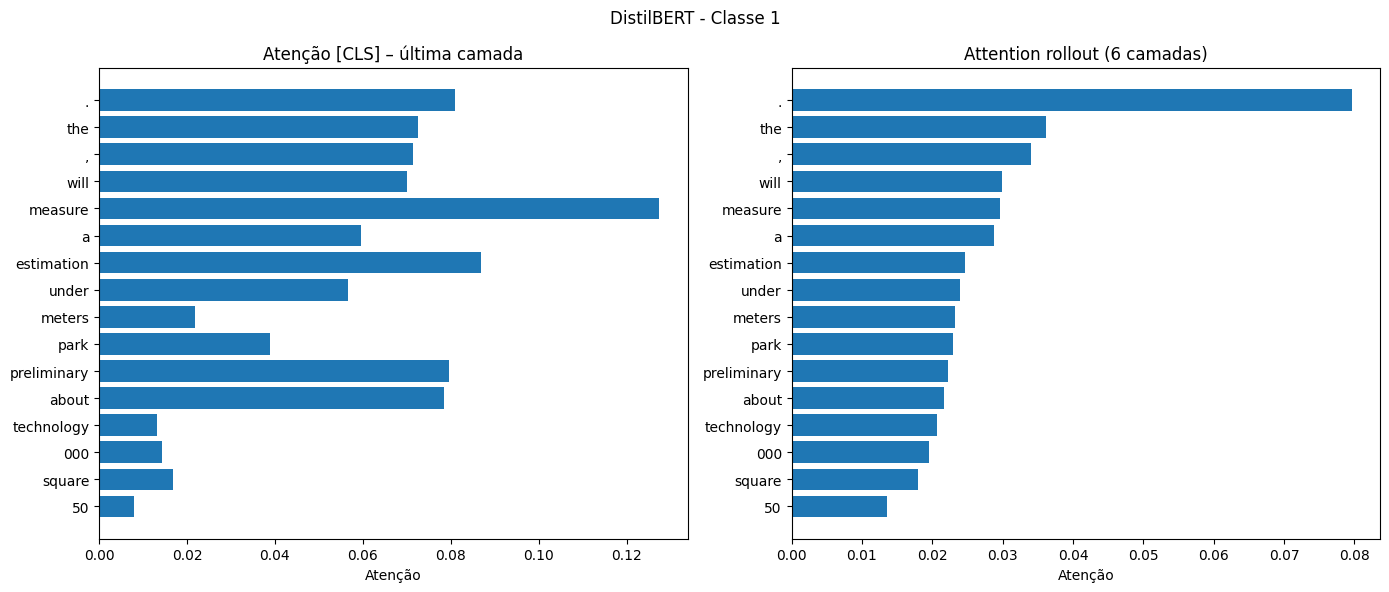

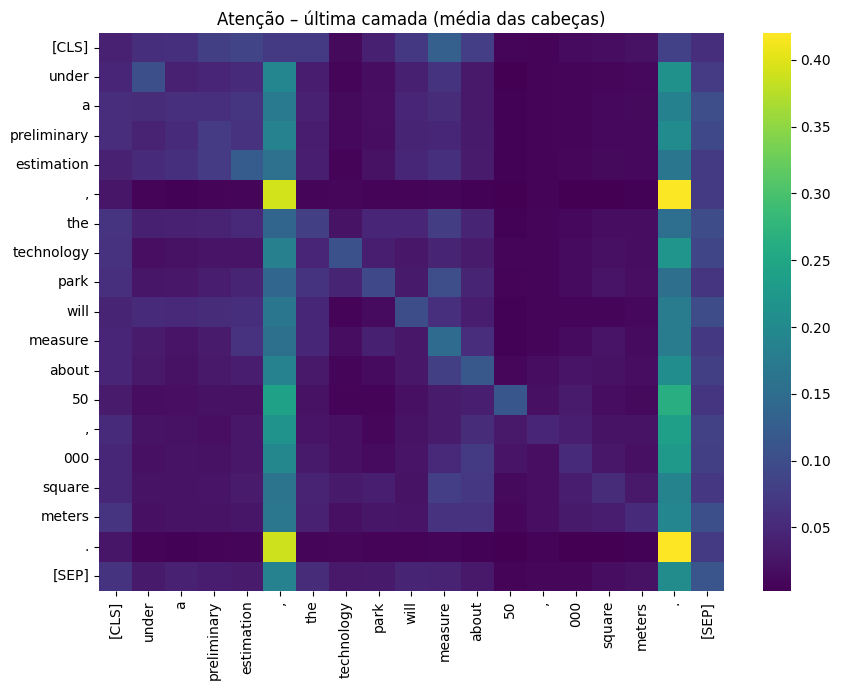

In [28]:
top = importancias.head(20)
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].barh(top["Feature"], top["Last layer [CLS]"])
ax[0].set_title("Atenção [CLS] – última camada"); ax[0].invert_yaxis()
ax[1].barh(top["Feature"], top["Rollout"])
ax[1].set_title("Attention rollout (6 camadas)"); ax[1].invert_yaxis()
for a in ax: a.set_xlabel("Atenção")
fig.suptitle(f"DistilBERT - Classe {predicted_class_index}")
plt.tight_layout(); plt.show()

# Mapa de calor da última camada (média das cabeças)
plt.figure(figsize=(9, 7))
sns.heatmap(att[-1].mean(0).numpy(), xticklabels=tokens, yticklabels=tokens, cmap="viridis")
plt.title("Atenção – última camada (média das cabeças)")
plt.tight_layout(); plt.show()

**Shapley**

In [29]:
lime_idx = 499
sample_text = X_test.iloc[lime_idx]

pred_class_idx = predict_proba([sample_text]).argmax(axis=1)[0]
print("Classe prevista:", pred_class_idx, le.classes_[pred_class_idx])

masker = shap.maskers.Text(tokenizer)
shap_explainer = shap.Explainer(lambda x: predict_proba(list(x)), masker,
                                output_names=list(le.classes_))

shap_values = shap_explainer([sample_text])

sv = shap_values[0, :, pred_class_idx]
words = np.array(sv.data)
values = np.array(sv.values)
expected_value = float(sv.base_values)

order = np.argsort(np.abs(values))[::-1][:15]
print("Palavras:", words[order])
print("SHAP:", values[order])
print("Valor base:", expected_value)

Classe prevista: 1 neutral



PartitionExplainer explainer: 2it [02:17, 137.90s/it]              

Palavras: ['square ' 'meters ' 'measure ' 'about ' 'preliminary ' '000 ' 'park '
 'a ' 'will ' '50' 'technology ' 'the ' 'Under ' ',' 'estimation ']
SHAP: [0.07814043 0.05553071 0.04908662 0.04430561 0.03887245 0.03863463
 0.03785222 0.02508271 0.02245062 0.0205531  0.0204274  0.01731171
 0.01201758 0.01123353 0.00929804]
Valor base: 0.47852805256843567


In [30]:
# Visualização interativa no texto
shap.plots.text(shap_values[0, :, pred_class_idx])

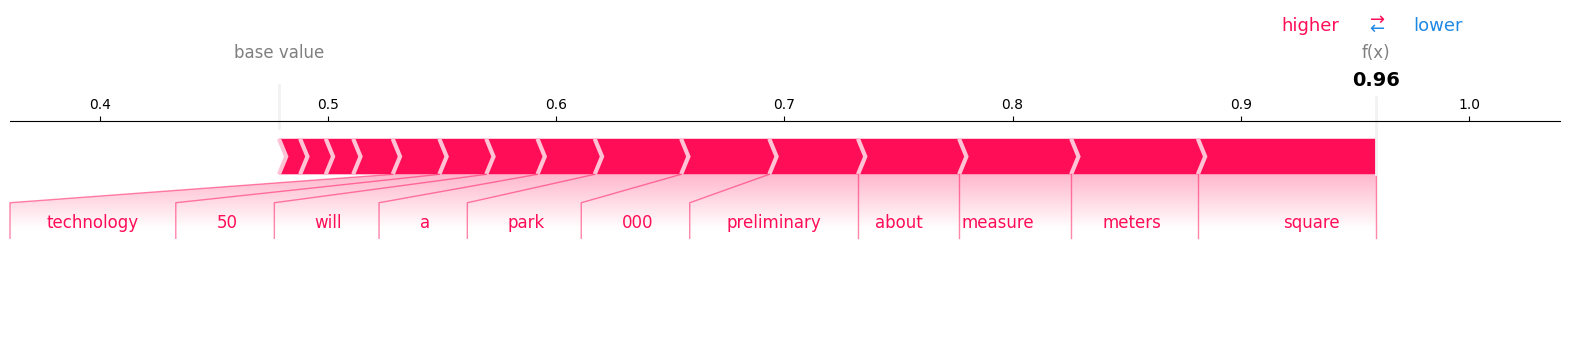

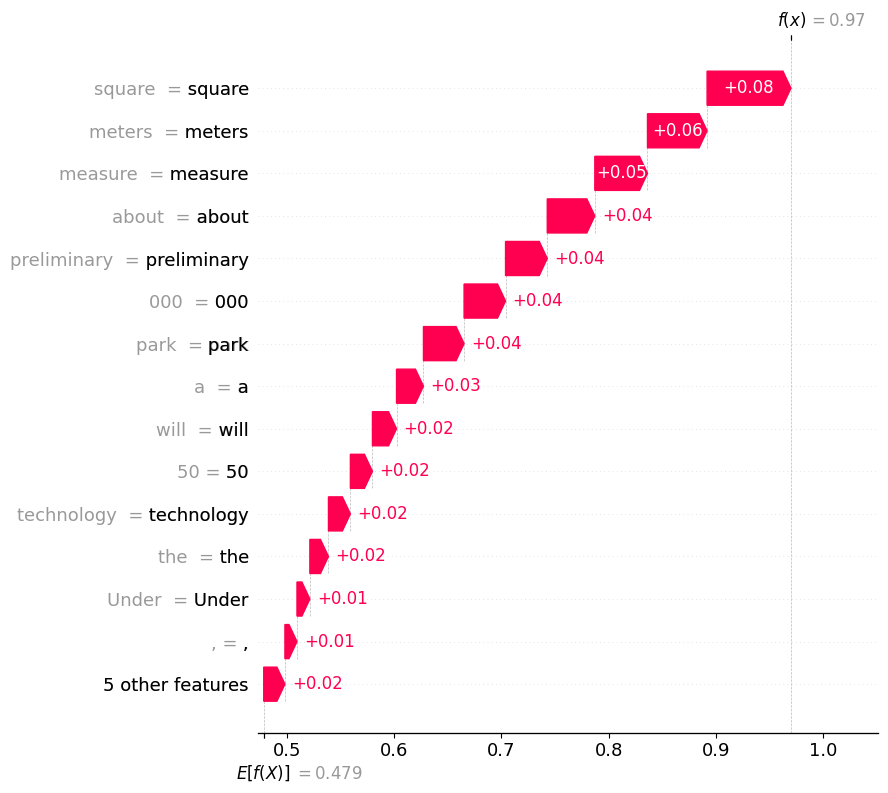

In [31]:
# Force plot (mesmo formato do notebook do MLP)
shap.force_plot(
    base_value=expected_value,
    shap_values=values[order],
    feature_names=[w.strip() for w in words[order]],
    matplotlib=True
)

# Waterfall
shap.plots.waterfall(sv, max_display=15)

**Salvar modelo e resultados** (para comparar os 5 modelos depois)

In [32]:
import json
model.save_pretrained("distilbert_imbalanced")
tokenizer.save_pretrained("distilbert_imbalanced")

resultados = {
    "modelo": "DistilBERT", "cenario": "imbalanced", "texto": TEXT_COLUMN,
    "accuracy": accuracy, "precision_w": precision, "recall_w": recall, "f1_w": f1,
    "f1_macro": f1_score(y_test, y_pred_classes, average="macro"),
    "epochs": EPOCHS, "lr": LR, "batch_size": BATCH_SIZE, "max_len": MAX_LEN,
}
with open("resultados_distilbert_imbalanced.json", "w") as f:
    json.dump(resultados, f, indent=2)
resultados

{'modelo': 'DistilBERT',
 'cenario': 'imbalanced',
 'texto': 'text',
 'accuracy': 0.8340206185567011,
 'precision_w': 0.8366549824103222,
 'recall_w': 0.8340206185567011,
 'f1_w': 0.8349818369118079,
 'f1_macro': 0.8126926439003482,
 'epochs': 3,
 'lr': 2e-05,
 'batch_size': 32,
 'max_len': 64}